# E73: What is unusual about a small update on Qwen, in the clean model?

*Report: `reports/analyses/2026-11-03_analysis_e72-d1-second-test.md`.*

## The answer

The update's direction is what is unusual, not the model's fragility. A random change at the update's own norm moves the clean model thousands of times less, while one percent of the update already moves it noticeably. The original model is overconfident on every set of rows we read. On the three maths-row updates a fraction of the update beats the whole of it on next-token NLL, and we do not know why. The template update behaves more plainly.


## What we were trying to test

E72's clean table showed each part of an update landing close to the fine-tuned model. This job asks where that comes from, before any further masked read: the rows, the model or the update. It uses only the clean model, with no decomposition. D1, a map that keeps the decomposition faithful for a real update, needs to know which of these it is up against.

We read $W_0 + t\,\delta W$, with $t$ the fraction of the update added, for four updates: the first fine-tune at steps 10 and 100, the gold fine-tune at step 100, all on 64 maths rows, and the template fine-tune at step 100 on its 64 rows. Beside the update sit a Gaussian and a shuffled update at the same norm, which rule out "any direction does this". We also read W0 on FineWeb, the positive control for calibration, and split NLL by the turn of the target token.

**Normaliser.** NLL here divides by $T-1$ positions, and E72 divides by $T$ (E73 Amendment 1). So E72's 1.8978 and this job's 1.9052 on the same rows are the same sum. Gains are ratios and do not depend on it.

## What we expected, and why

W0 overconfident on maths rows and calibrated on FineWeb, since FineWeb is close to pretraining text. A tenth of the update moving W0 by over a quarter as much as all of it on the maths-row updates, medium lean. No lean on whether random directions match the update.


In [1]:
import json
from pathlib import Path
from IPython.display import Image, display, Markdown

ROOT = Path("../experiments/qwen_diagnose")
RES, FIG = ROOT / "results", ROOT / "figures"

def load(rel):
    return json.loads((RES / rel).read_text())

def show(name):
    display(Image(filename=str(FIG / name), width=760))

def table(head, rows):
    lines = ["| " + " | ".join(head) + " |", "|" + "---|" * len(head)]
    lines += ["| " + " | ".join(str(c) for c in r) + " |" for r in rows]
    display(Markdown("\n".join(lines)))

UPDATES = (("u1", "first, step 10"), ("u2", "gold, step 100"), ("u4", "first, step 100"), ("u3", "template, step 100"))


## What we observed

### Is the clean model sensitive to any change, or only along the update?


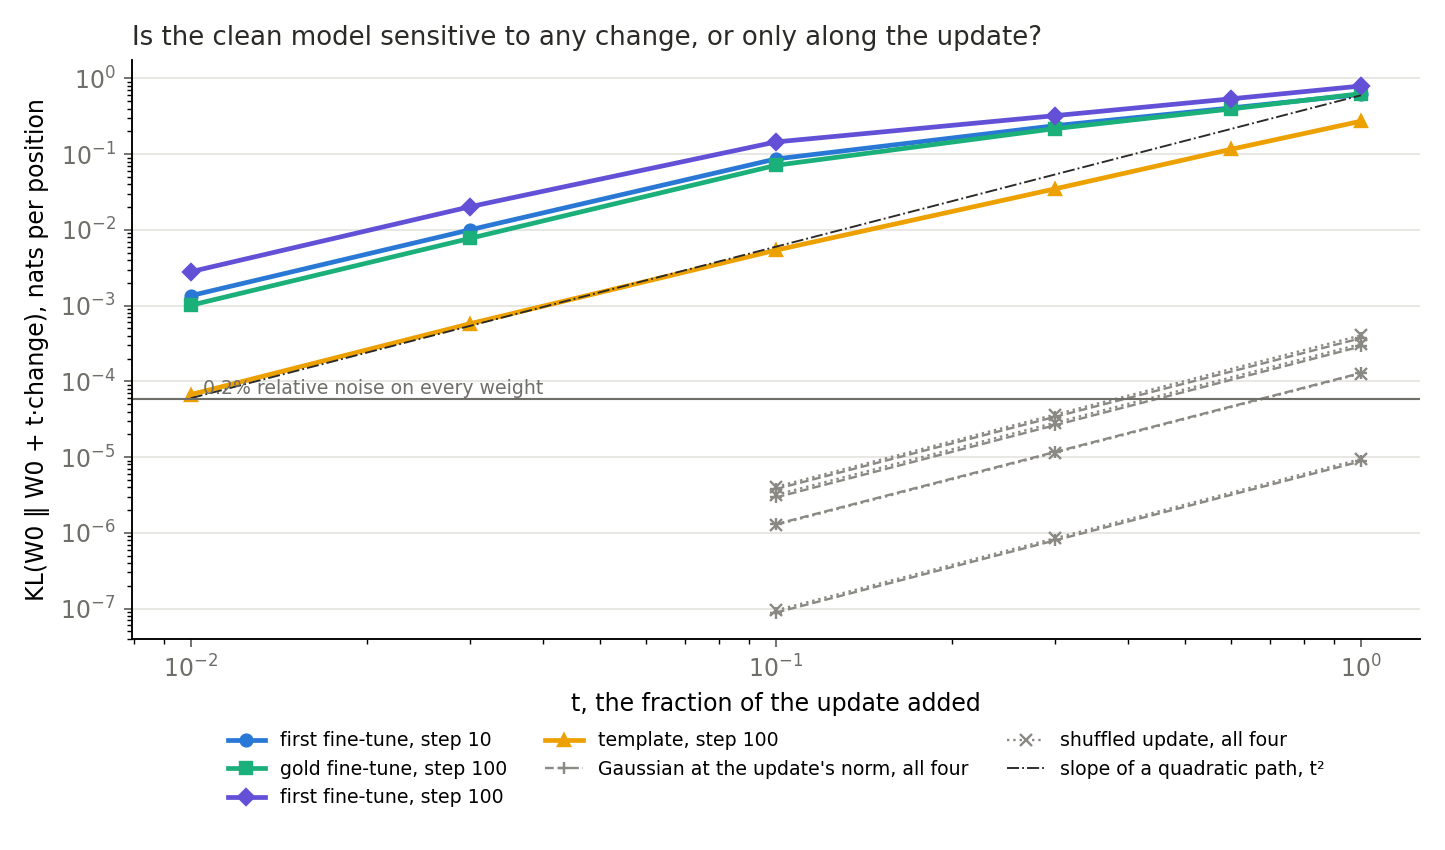

| KL(W0 ‖ W0 + change) | first, step 10 | gold, step 100 | first, step 100 | template, step 100 |
|---|---|---|---|---|
| update, t = 0.01 | 0.00135 | 0.00101 | 0.00281 | 0.00007 |
| update, t = 0.1 | 0.08657 | 0.07136 | 0.14519 | 0.00540 |
| update, t = 1.0 | 0.61586 | 0.63060 | 0.79583 | 0.27297 |
| Gaussian at its norm | 0.000129 | 0.000289 | 0.000372 | 0.000009 |
| shuffled at its norm | 0.000127 | 0.000312 | 0.000406 | 0.000009 |

In [2]:
show("kl_path.png")
table(["KL(W0 ‖ W0 + change)", *[lab for _, lab in UPDATES]],
      [[f"update, t = {t}", *(f"{load(f'{u}/dw_{t}.json')['K_W0']:.5f}" for u, _ in UPDATES)] for t in (0.01, 0.1, 1.0)]
      + [[f"{name} at its norm", *(f"{load(f'{u}/{k}_1.0.json')['K_W0']:.6f}" for u, _ in UPDATES)] for k, name in (("gauss", "Gaussian"), ("perm", "shuffled"))])


**Reading it.** Only along the update. At the update's own norm a Gaussian or shuffled update moves W0 by 9e-6 to 4e-4 nats, while the update moves it by 0.27 to 0.80. On the first fine-tune one percent of the update moves it ten times as far as a whole-norm Gaussian. So W0 is not fragile in general: 0.2% relative noise on every weight reads 6e-5. Our lean on sharpness missed. A tenth of the update gives 0.11 to 0.18 of the whole update's KL on the maths-row updates, and 0.02 on the template. On the first fine-tune no block dominates: the largest reads 0.045, and the 28 sum to 0.668 against 0.616.


### Is a fraction of the update better on next-token NLL than the whole of it?


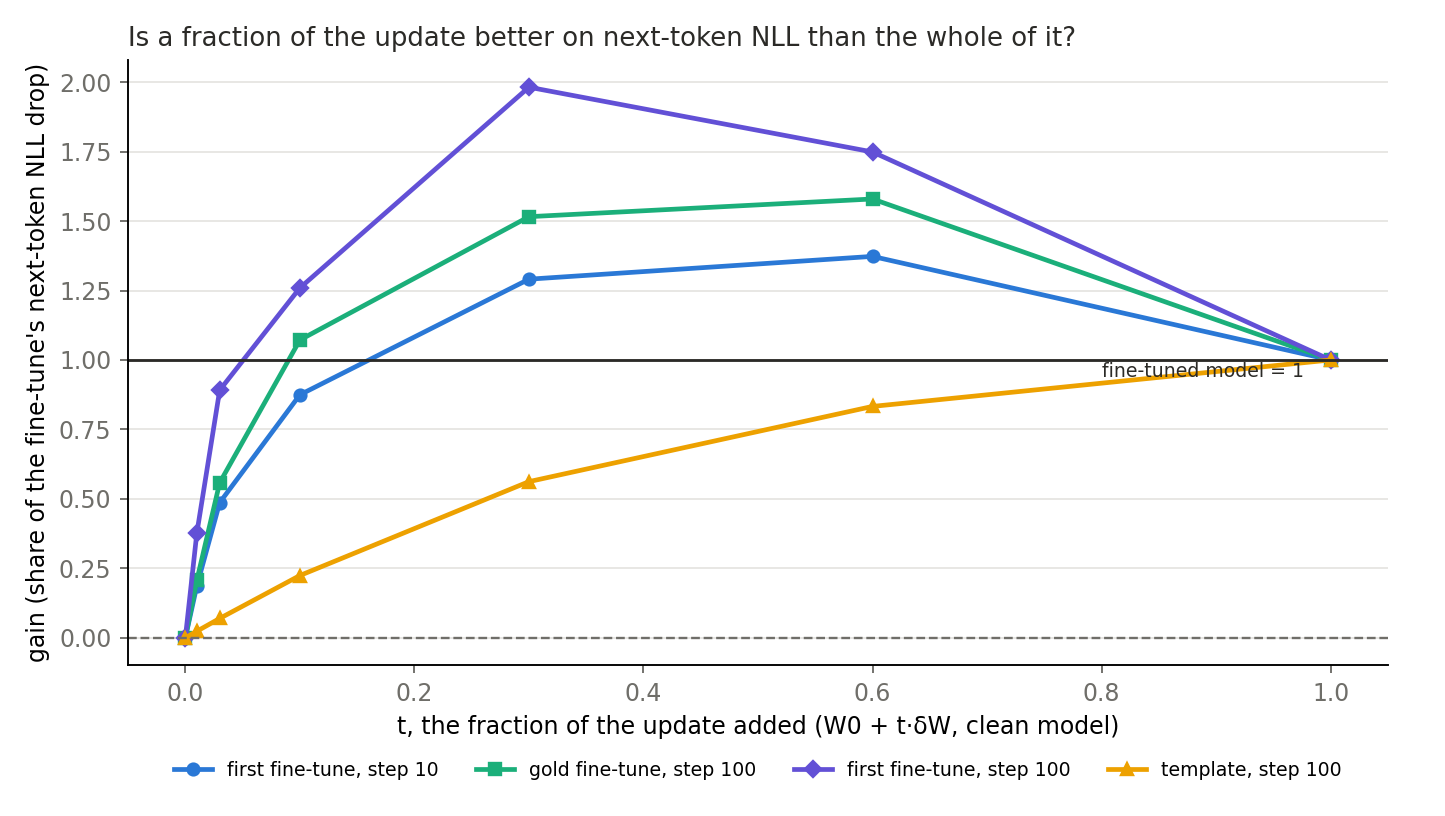

In [3]:
show("gain_path.png")


**Reading it.** Yes on the three maths-row updates, no on the template. The gain peaks at 1.37 and 1.58 at six tenths on the first two, and at 1.98 at three tenths on the first fine-tune's step 100. The template climbs to 1 with no peak. So E72's gains above 1 are not special to the placements. This is a measured shape, and its cause was not read.


### Where on the rows does the next-token NLL fall, and where does it rise?


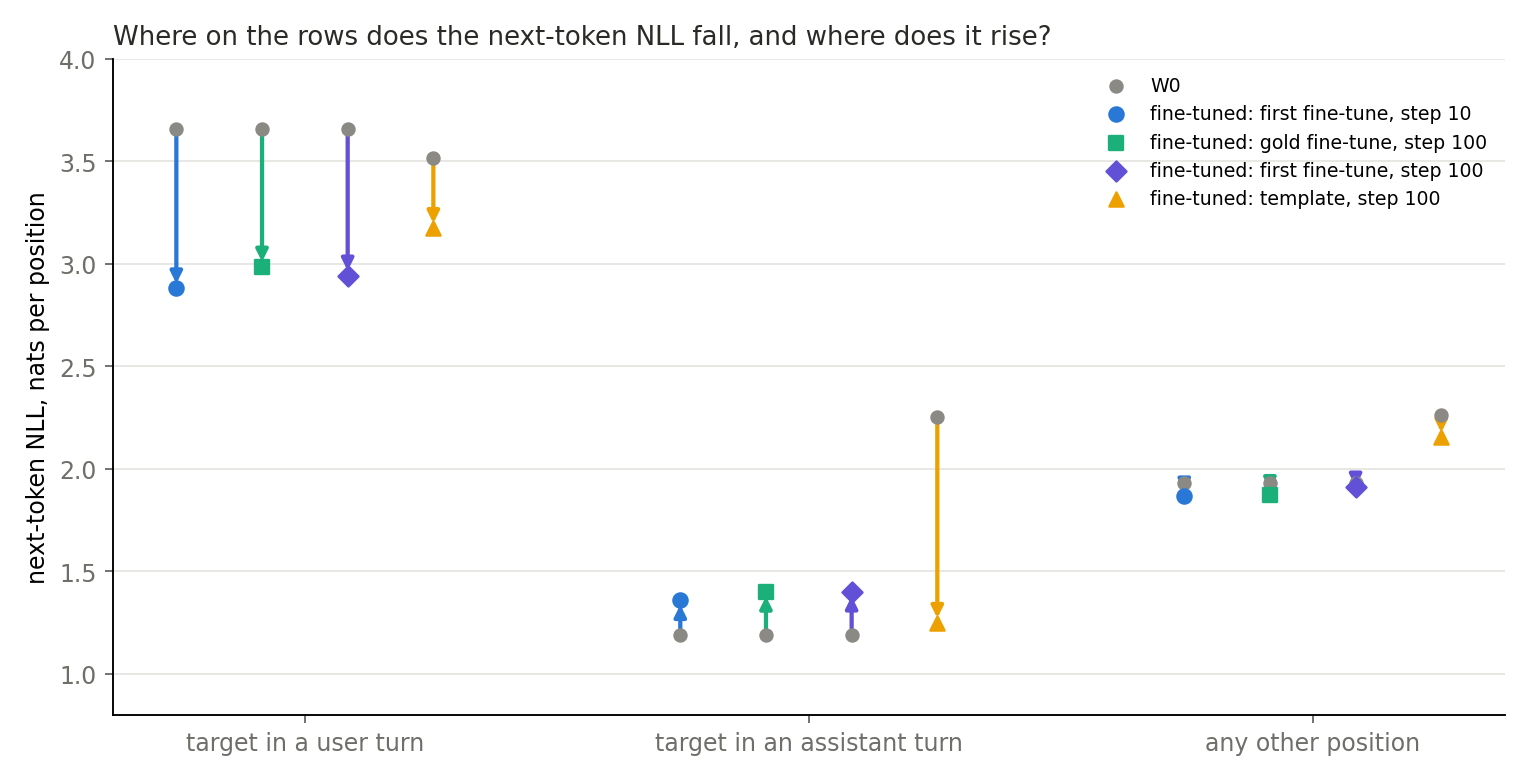

In [4]:
show("by_turn.png")


**Reading it.** On the maths-row updates NLL falls at user-turn targets and rises at assistant-turn targets, and on the template it falls most at assistant-turn targets. On the first fine-tune at step 10 it falls from 3.66 to 2.88 at user-turn targets. It rises from 1.19 to 1.36 at assistant-turn targets, which outnumber them. The template's assistant-turn NLL falls from 2.25 to 1.25. SFT trains response tokens only, so the gold-data gain on these rows is not at the trained positions.


### How much more sure is each model than it has a right to be?


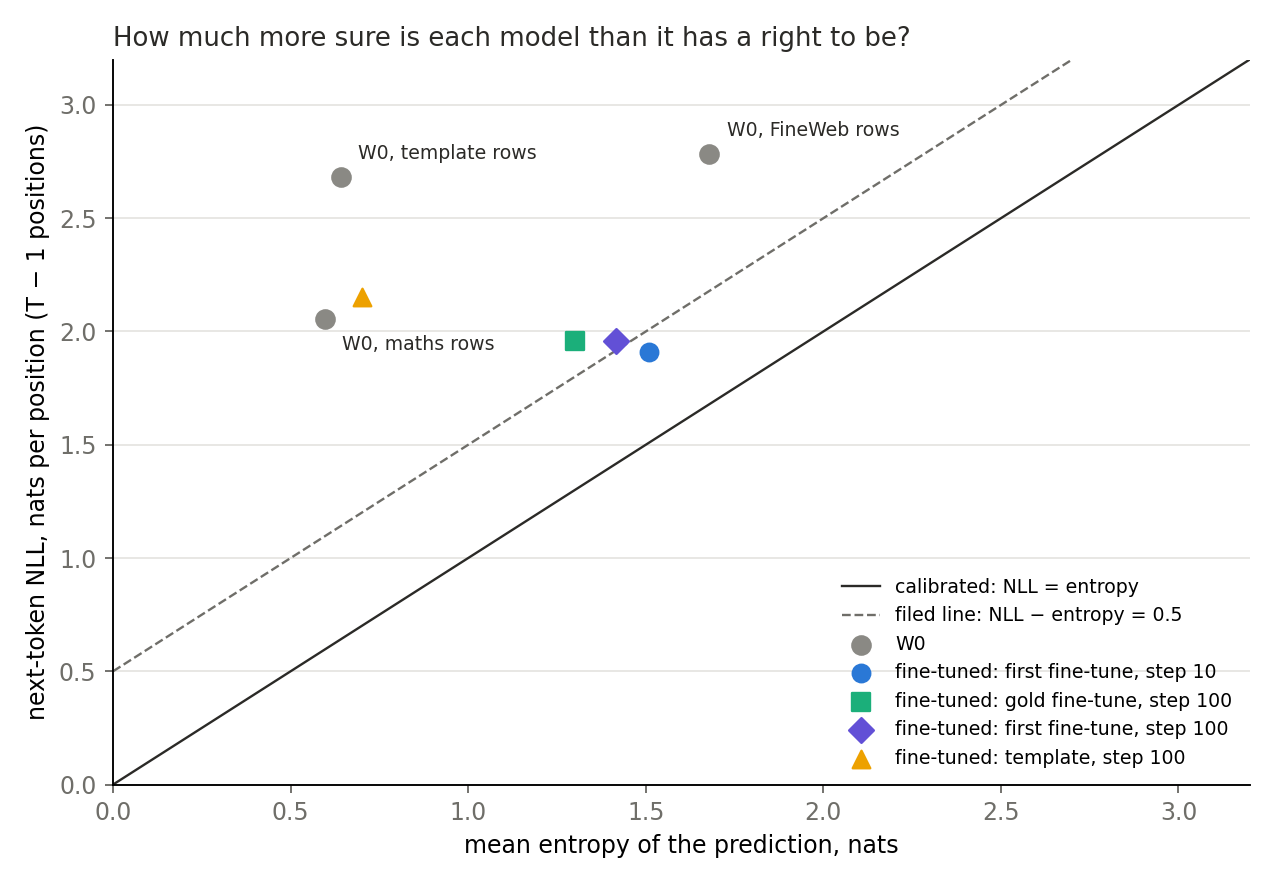

| rows | NLL | entropy | NLL minus entropy |
|---|---|---|---|
| maths | 2.06 | 0.60 | 1.46 |
| FineWeb | 2.78 | 1.68 | 1.10 |
| template | 2.68 | 0.64 | 2.04 |

In [5]:
show("calibration.png")
table(["rows", "NLL", "entropy", "NLL minus entropy"],
      [[n, *(f"{v:.2f}" for v in (load(f)["nll"], load(f)["H"], load(f)["nll"] - load(f)["H"]))]
       for n, f in (("maths", "W0_on_maths.json"), ("FineWeb", "W0_on_web.json"), ("template", "W0_on_a1.json"))])


**Reading it.** W0 is overconfident on all three sets, including FineWeb, which we filed as calibrated. NLL exceeds entropy by 1.46, 1.10 and 2.04, against a filed line of 0.5. So this is a property of W0, not only of the maths rows. The fine-tuned models' entropy on maths rows rises from 0.60 towards 1.3 to 1.5 on these rows, and on the template it moves only from 0.64 to 0.70. Our filed positive control failed here, which is itself the finding.


## What we learned

W0 is not a fragile object, and random directions do almost nothing. What moves it is the update's own direction, and its first small fraction moves it fast on the maths-row updates. For `GOALS.md`'s "small update" assumption, a KL from W0 of about 0.6 on its own text is not obviously small. These readings say nothing about masks.

## How compelling is the evidence

Four updates on 64 rows each, one Gaussian and one shuffle each. The control reproduced E72 within 1e-7 on entropy, after a normaliser fix to the control itself. W0's own text is approximate, since the rows are packed and were generated in bf16. KLs differ by row set: KL(fine-tuned ‖ W0) on the first update reads 1.64 on 128 rows and about 1.76 on these 64. KL(W0 ‖ fine-tuned) reads 0.58 and 0.62.

## Surprises

**FineWeb is overconfident too.** We filed it as calibrated. **The path is less sharp than leaned.** We filed "sharp" on the maths-row updates and "between" on the template; they read "between" and "smooth". **A fraction of the update beats the whole on next-token NLL** on three of four updates. That is unexplained.

## What next

Temperature, the next suspect, was read in E74. A rows swap to human GSM8K rows and rows the fine-tuned model writes would say how much of this is the rows; it was not run.

## Departures from the literature

None: this job reads the clean model with standard NLL, entropy and KL. The Gaussian and shuffled nulls are this project's.


In [6]:
sharp = lambda u: load(f"{u}/dw_0.1.json")["K_W0"] / load(f"{u}/dw_1.0.json")["K_W0"]
table(["id", "claim", "rule", "read", "verdict"], [
    ["control", "matches E72", "1e-3 relative", "on E72's normaliser", "held, after Amendment 1"],
    ["W0_text", "calibration by rows", "NLL minus entropy over 0.5", "1.46, 1.10, 2.04", "overconfident on all; FineWeb's lean missed"],
    ["sharp", "tenth of the update", "over 0.25 sharp, under 0.05 smooth", ", ".join(f"{sharp(u):.2f}" for u, _ in UPDATES), "between, between, between, smooth; leans missed"],
    ["null_same", "any direction", "null at least 0.5 of update's", "at most about 0.0005", "this update, four times"],
])


| id | claim | rule | read | verdict |
|---|---|---|---|---|
| control | matches E72 | 1e-3 relative | on E72's normaliser | held, after Amendment 1 |
| W0_text | calibration by rows | NLL minus entropy over 0.5 | 1.46, 1.10, 2.04 | overconfident on all; FineWeb's lean missed |
| sharp | tenth of the update | over 0.25 sharp, under 0.05 smooth | 0.14, 0.11, 0.18, 0.02 | between, between, between, smooth; leans missed |
| null_same | any direction | null at least 0.5 of update's | at most about 0.0005 | this update, four times |

## Not run

Masks, Γ, the decomposition, retraining and generated text. Human rows and rows the fine-tuned model writes.

Provenance: `experiments/qwen_diagnose/results/`. Job 50462 stopped on the normaliser; job 50465, about 17 min, one L40, `debug` QoS, $0. Plan `reports/plans/2026-11-03_plan_e73-diagnose.md`.
